In [ ]:
# %pip install torch torchvision torchaudio

# need to run on your laptop to install torch so we can import it

In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from torch.utils.data import Dataset, DataLoader

In [5]:
df = pd.read_csv("AirportFootfalls_data.csv")

<function matplotlib.pyplot.show(close=None, block=None)>

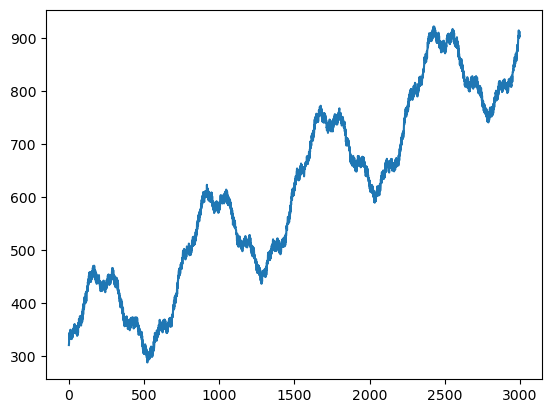

In [6]:
plt.plot(df['Passenger Traffic (x100 passengers)'])
plt.show

In [7]:
series = df['Passenger Traffic (x100 passengers)'].values #so don't have to worry about index that may cause bugs

n = len(series)
train_end = int(n*0.7) 
validation_end = int(n*0.85)

train_data = series[:train_end]
validation_data = series[train_end:validation_end]
test_data = series [validation_end:]
#70-15-15 split

print(f"Train shape: {train_data.shape}")
print(f"Validation shape: {validation_data.shape}")
print(f"Test shape: {test_data.shape}")

Train shape: (2100,)
Validation shape: (450,)
Test shape: (450,)


In [13]:
#reshape 1D array (series) to 2D array so we can use for scikit learn

train_2d = train_data.reshape(-1,1)
validation_2d = validation_data.reshape(-1,1)
test_2d = test_data.reshape(-1,1)

#need scaler to squish output values between 0 and 1 so gradient descent works as it should later - no exploding gradient
scaler = MinMaxScaler(feature_range=(0,1)) #scale range is 0 to 1

train_scaled = scaler.fit_transform(train_2d) 
validation_scaled = scaler.transform(validation_2d) #didn't use fit here becuase we shouldn't see/know "future" data
test_scaled = scaler.transform(test_2d)


In [ ]:
#Feature Engineering to feed values in DL model
# input output pairs - like table in #2
# using lag / window size = 4 becuase this is what the example table looked like
# Sample output: X = [x1, x2, x3, x4], y = x5

class TSDataset(Dataset):
    def __init__(self, data, window_size):
        self.X = []
        self.y = []
        flatten_data = data.flatten() #make sure data is 1D to make index slicing easier

        for i in range(len(flatten_data) - window_size):
            self.X.append(flatten_data[i:i+window_size])
            self.y.append(flatten_data[i+window_size])
        #this loops makes 
        # 1) X which is 4 consecutive data points like [x_t, x_t+1, x_t+2, x_t+3] and 
        # 2) y the target value whcih is the value immediately after X like [x+t+4]

        #converting to PyTorch Tensors. Since doing a regression use float32
        self.X = torch.tensor(np.array(self.X), dtype=torch.float32)
        self.y = torch.tensor(np.array(self.y), dtype=torch.float32).unsqueeze(1) #unsqueen to turn y 2D like how X is

    #so pytorch now how my X,y pairs there are
    def __len__(self):
        return len(self.X)

    #so pytorch can grab a singular X,y pair
    def __getitem__(self, index):
        return self.X[index], self.y[index]

#creates X,y pair for full dataset
#initalize sliding window dataset using lag=4
train_dataset = TSDataset(train_scaled, 4)
validation_dataset = TSDataset(validation_scaled, 4)
test_dataset = TSDataset(test_scaled, 4)

#create pytorch dataloaders; batch size = 32 (arbitary), since time series we use shuffle = false (keep in chronological order)
train_loader = DataLoader(train_dataset, 32, shuffle=False)
validation_loader = DataLoader(validation_dataset, 32, shuffle=False)
test_loader = DataLoader(test_dataset, 32, shuffle=False)

print(f"Sample Batch X shape: {train_dataset.X.shape}")
print(f"Sample Batch y shape: {train_dataset.y.shape}")

Sample Batch X shape: torch.Size([2096, 4])
Sample Batch y shape: torch.Size([2096, 1])
